# The SDP relaxation for collision-free motion planning

An executable walk through Graesdal, Amice, Parrilo & Tedrake,
[*Semidefinite Relaxations for Collision-Free Motion Planning*](https://arxiv.org/abs/2606.14063) (arXiv:2606.14063).

The paper turns a nonconvex path-planning problem into a convex semidefinite program (SDP), and then
explains exactly **what that SDP solves**: the same planning problem, but in a space with extra
dimensions where a path is allowed to go *around* an obstacle "from above". This notebook focuses on
that relaxation. The machinery that leads to it is built briefly; most of the space goes to solving the
relaxation on the smallest example where something interesting happens, and reading the answer through
the paper's theorems.

By the end you will have seen, on one example you can check by hand:
- the relaxation return the **correct optimal cost**;
- the returned curve itself pass **straight through the obstacle**;
- why both are true at once (a path in three dimensions that hops over the obstacle);
- how to get a valid planar path back.

## 1. The big picture

### 1.1 The problem (Sec. III-A, eq. 1)

The paper plans a path $q:[0,1]\to\mathbb R^n$ for a point robot among $m$ spherical obstacles with
centres $c_j\in\mathbb R^n$ and radii $r_j>0$:

$$
\begin{aligned}
\min_q\quad & \int_0^1 \|q^{(k)}(s)\|_2^2\,ds && \text{(1a)}\\
\text{s.t.}\quad & \|q(s)-c_j\|_2^2-r_j^2\ \ge 0 \quad \forall s\in[0,1],\ j=1,\dots,m && \text{(1b, 1c)}\\
& q^{(i)}(0)=q_0^{(i)},\quad q^{(i)}(1)=q_1^{(i)},\quad i=0,\dots,\ell && \text{(1d, 1e)}\\
& q\in\mathcal C^\eta. && \text{(1f)}
\end{aligned}
$$

In words:
- **(1a)** The cost is how much the $k$-th derivative of the path is nonzero, summed over the whole path:
  $k=1$ is minimum energy (short, evenly paced paths), $k=2$ minimum acceleration, $k=4$ minimum snap.
- **(1b)** At *every* instant $s$ the robot must be at least $r_j$ away from obstacle centre $c_j$.
- **(1d, 1e)** The path starts and ends at prescribed positions (and, up to order $\ell$, derivatives).
- **(1f)** The path is $\eta$ times continuously differentiable.

### 1.2 Why it is hard

Three things stand in the way, and each step of the paper removes one.

1. **The unknown is a function.** $q$ has infinitely many degrees of freedom.
2. **Infinitely many constraints.** (1b) must hold at every $s\in[0,1]$, not at a few samples.
3. **Nonconvexity.** The set of points *outside* a ball is not convex: the average of a path going left of
   an obstacle and a path going right of it goes straight through it. So local solvers can get stuck,
   and there is no certificate that a solution is globally optimal.

### 1.3 The paper's chain of steps

| step | what it does | removes | paper |
|---|---|---|---|
| 1 | write $q$ as a polynomial curve $\gamma(s)=\Gamma b_d(s)$; the unknown becomes the matrix $\Gamma$ | infinite dimension | Sec. III-B, C (eqs. 2–5) |
| 2 | collect cost and constraints in $\Gamma$: a QCQP with a constraint for every $s$ | | Sec. III-D (eq. 8) |
| 3 | replace "$p(s)\ge0$ for all $s$" by an exact sum-of-squares certificate with Gram matrices $Q_0,Q_1\succeq0$ | infinitely many constraints | Sec. IV (Lemma 2) |
| 4 | the result, problem (P), is nonconvex **only** through the product $\Gamma^T\Gamma$; replace it by a new matrix $X\succeq\Gamma^T\Gamma$ | nonconvexity | Sec. V (SDP) |
| 5 | explain what the relaxation solves: the same problem with $\rho$ extra dimensions | | Sec. VI-A (Thms 1–3) |
| 6 | say exactly when it is tight, and when the optimal path can be read off | | Sec. VI-B, C (Thms 4–5) |

Steps 1–3 are exact reformulations: nothing is lost. Step 4 is the only approximation, and steps 5–6
explain precisely what it loses.

### 1.4 Roadmap of this notebook

- **Section 2** builds steps 1–3 compactly: just the functions the relaxation needs.
- **Section 3** is the core: problem (P), the lift to $X$, and the higher-dimensional reading of the SDP.
- **Section 4** solves the smallest interesting example and reads the solution through Theorems 3–5.
- **Section 5** summarises.

## Setup

The kernel starts Julia in this folder's environment (`notebooks/Project.toml`), so only the packages
need loading. JuMP models the SDP, Hypatia solves it, Plots draws.

In [1]:
using LinearAlgebra
using JuMP, Hypatia
using Plots

## 2. Steps 1–3: from a path to a finite problem in $\Gamma$

*Where we are:* before we can relax anything we need the problem written in terms of a matrix of
numbers. This section does that, following the paper, and keeps only what Section 3 uses.

### 2.1 Polynomial curves in the Bernstein basis (eqs. 2, 25)

Each path segment is a polynomial curve of degree $d$,

$$\gamma(s)=\Gamma\,b_d(s),\qquad \Gamma\in\mathbb R^{n\times(d+1)},\qquad
b_d(s)=\big[B_0^d(s),\dots,B_d^d(s)\big]^T,\qquad B_i^d(s)=\binom di s^i(1-s)^{d-i}. \tag{2, 25}$$

The columns of $\Gamma$ are the **control points**. Each $B_i^d$ is a bump on $[0,1]$, the bumps are
never negative and sum to one (eq. 31: $e^Tb_d(s)=1$), so $\gamma(s)$ is a weighted average of the
control points. In particular $\gamma(0)$ is the first control point and $\gamma(1)$ the last.

The paper indexes $i=0,\dots,d$; in Julia, control point $i$ is column `i+1` of `Γ`.

In [2]:
B(d, i, s) = binomial(d, i) * s^i * (1 - s)^(d - i)
b(d, s) = [B(d, i, s) for i in 0:d]
γ(Γ, s) = Γ * b(size(Γ, 2) - 1, s)

γ (generic function with 1 method)

**Tiny example: the Bernstein basis for $d=2$.** With $d=2$ there are three basis polynomials:

$$B_0^2(s)=(1-s)^2,\qquad B_1^2(s)=2s(1-s),\qquad B_2^2(s)=s^2.$$

Things to notice, all visible in the plot below:
- **Each is a bump** that is never negative on $[0,1]$. $B_i^2$ is largest at $s=i/2$: $B_0^2$ at the start,
  $B_1^2$ in the middle, $B_2^2$ at the end.
- **They always add up to one**: $(1-s)^2+2s(1-s)+s^2=\big((1-s)+s\big)^2=1$.
- **At the ends only one survives**: $b_2(0)=(1,0,0)$ and $b_2(1)=(0,0,1)$.

By hand at $s=\tfrac12$: $B_0^2=\tfrac14$, $B_1^2=2\cdot\tfrac12\cdot\tfrac12=\tfrac12$, $B_2^2=\tfrac14$.
So $b_2(\tfrac12)=(\tfrac14,\tfrac12,\tfrac14)$, which sums to $1$.

s = 0.0:  b_2(s) = [1.0, 0.0, 0.0]   sum = 1.0
s = 0.25:  b_2(s) = [0.5625, 0.375, 0.0625]   sum = 1.0
s = 0.5:  b_2(s) = [0.25, 0.5, 0.25]   sum = 1.0
s = 1.0:  b_2(s) = [0.0, 0.0, 1.0]   sum = 1.0


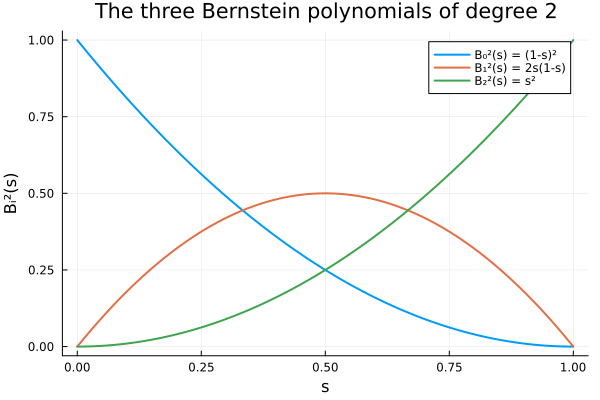

In [3]:
for s in (0.0, 0.25, 0.5, 1.0)
    println("s = ", s, ":  b_2(s) = ", b(2, s), "   sum = ", sum(b(2, s)))
end
plot(0:0.01:1, [[B(2, i, s) for s in 0:0.01:1] for i in 0:2];
     label = ["B₀²(s) = (1-s)²" "B₁²(s) = 2s(1-s)" "B₂²(s) = s²"],
     xlabel = "s", ylabel = "Bᵢ²(s)", title = "The three Bernstein polynomials of degree 2", lw = 2)

**Tiny example: a curve is a weighted average of its control points.** Take the curve used in Section 4,

$$\Gamma=\begin{bmatrix}-2&0&2\\0&1&0\end{bmatrix},\qquad\text{control points } \gamma_0=(-2,0),\ \gamma_1=(0,1),\ \gamma_2=(2,0).$$

Then $\gamma(s)=B_0^2(s)\,\gamma_0+B_1^2(s)\,\gamma_1+B_2^2(s)\,\gamma_2$: at each $s$ the basis values are
the weights given to each control point.

By hand at $s=\tfrac12$ the weights are $(\tfrac14,\tfrac12,\tfrac14)$, so
$\gamma(\tfrac12)=\tfrac14(-2,0)+\tfrac12(0,1)+\tfrac14(2,0)=(0,\tfrac12)$.

The curve starts at $\gamma_0$ and ends at $\gamma_2$ (only one weight is nonzero there), but it does
**not** pass through $\gamma_1$: in the middle, $\gamma_1$ only gets half the weight, so the curve reaches
halfway to it. Control points pull the curve; they are not waypoints.

γ(1/2) = [0.0, 0.5]   (by hand: (0, 0.5))


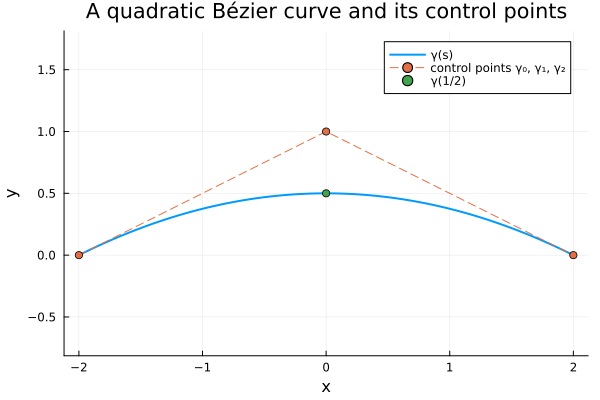

In [4]:
Γbent = [-2.0 0.0 2.0; 0.0 1.0 0.0]
println("γ(1/2) = ", γ(Γbent, 0.5), "   (by hand: (0, 0.5))")
curve = [γ(Γbent, s) for s in 0:0.01:1]
plot(first.(curve), last.(curve); label = "γ(s)", lw = 2, aspect_ratio = :equal,
     xlabel = "x", ylabel = "y", title = "A quadratic Bézier curve and its control points")
plot!(Γbent[1, :], Γbent[2, :]; ls = :dash, marker = :circle, label = "control points γ₀, γ₁, γ₂")
scatter!([0.0], [0.5]; label = "γ(1/2)")

### 2.2 The cost is linear in $\Gamma^T\Gamma$ (eqs. 3, 28–30)

Derivatives of a Bézier curve are Bézier curves of lower degree whose control points are differences of
neighbouring control points (eq. 28). Integrating the square of the $k$-th derivative gives

$$\int_0^1\|\gamma^{(k)}(s)\|_2^2\,ds=\operatorname{tr}\!\big(G^{(k)}\,\Gamma^T\Gamma\big),\qquad
G^{(k)}=\Big(\frac{d!}{(d-k)!}\Big)^2 D_d^{(k)}\,G_{d-k}\,\big(D_d^{(k)}\big)^T,\qquad
[G_d]_{ij}=\frac{1}{2d+1}\frac{\binom di\binom dj}{\binom{2d}{i+j}}. \tag{3, 29, 30}$$

$D_d\in\mathbb R^{(d+1)\times d}$ has $-1$ on the diagonal and $1$ on the subdiagonal, so $\Gamma D_d$
lists neighbour differences; $D_d^{(k)}=D_dD_{d-1}\cdots D_{d-k+1}$ takes differences $k$ times.

**Remember this:** the cost depends on $\Gamma$ only through the $(d+1)\times(d+1)$ matrix
$\Gamma^T\Gamma$ of inner products between control points. That is what makes step 4 possible.

In [5]:
D(d) = diagm(d + 1, d, 0 => -ones(d), -1 => ones(d))
G(d) = [binomial(d, i) * binomial(d, j) / ((2d + 1) * binomial(2d, i + j)) for i in 0:d, j in 0:d]

function Gk(d, k)
    Dk = prod((D(j) for j in d:-1:(d - k + 1)); init = Matrix(1.0I, d + 1, d + 1))
    return (factorial(d) / factorial(d - k))^2 * Dk * G(d - k) * Dk'
end

Gk (generic function with 1 method)

For the example in Section 4 we use $d=2$ (quadratic curves) and $k=1$ (energy). The matrix below is the
whole cost: $\operatorname{tr}(G^{(1)}\Gamma^T\Gamma)$. As a check, the straight segment from $(-2,0)$ to
$(2,0)$ has constant velocity $(4,0)$, so its cost must be $4^2=16$.

In [6]:
display(Gk(2, 1))
Γstraight = [-2.0 0.0 2.0; 0.0 0.0 0.0]
println("cost of the straight segment: ", tr(Gk(2, 1) * Γstraight' * Γstraight), "   (by hand: 16)")

3×3 Matrix{Float64}:
  1.33333   -0.666667  -0.666667
 -0.666667   1.33333   -0.666667
 -0.666667  -0.666667   1.33333

cost of the straight segment: 16.0   (by hand: 16)


**Tiny example: derivative and cost of the same curve.** For $d=2$ the difference matrix is

$$D_2=\begin{bmatrix}-1&0\\1&-1\\0&1\end{bmatrix},\qquad
\Gamma D_2=\big[\gamma_1-\gamma_0,\ \ \gamma_2-\gamma_1\big]=\begin{bmatrix}2&2\\1&-1\end{bmatrix}.$$

Multiplying by $D_2$ takes differences of neighbouring control points. By eq. (28) with $k=1$, the velocity is
a degree-1 Bézier curve whose control points are $d=2$ times those differences:

$$\gamma'(s)=2\,\Gamma D_2\,b_1(s)=2\big[(1-s)(2,1)+s(2,-1)\big]=(4,\ 2-4s).$$

The horizontal speed is constant ($4$); the vertical velocity goes from $+2$ (rising) to $-2$ (falling).
The cost is then, by hand,

$$\int_0^1\|\gamma'(s)\|^2ds=\int_0^1\big(16+(2-4s)^2\big)ds=16+\tfrac43=\tfrac{52}{3}\approx17.333.$$

The cell computes the same number two ways: by adding up $\|\gamma'(s)\|^2$ on a fine grid, and with the
matrix formula $\operatorname{tr}(G^{(1)}\Gamma^T\Gamma)$.

In [7]:
display(D(2))
display(Γbent * D(2))
velocity(s) = 2 * Γbent * D(2) * b(1, s)
println("γ'(0) = ", velocity(0.0), ",  γ'(1) = ", velocity(1.0), "   (by hand: (4, 2) and (4, -2))")
grid = range(0, 1; length = 100_001)
println("cost by summing on a grid:   ", sum(sum(abs2, velocity(s)) for s in grid) / length(grid))
println("cost by tr(G⁽¹⁾ΓᵀΓ):          ", tr(Gk(2, 1) * Γbent' * Γbent))
println("by hand 52/3:                ", 52 / 3)

3×2 Matrix{Float64}:
 -1.0   0.0
  1.0  -1.0
  0.0   1.0

2×2 Matrix{Float64}:
 2.0   2.0
 1.0  -1.0

γ'(0) = [4.0, 2.0],  γ'(1) = [4.0, -2.0]   (by hand: (4, 2) and (4, -2))
cost by summing on a grid:   17.333360000000066
cost by tr(G⁽¹⁾ΓᵀΓ):          17.333333333333336
by hand 52/3:                17.333333333333332


### 2.3 Avoiding an obstacle at every $s$ (eqs. 6–8)

Write the clearance from an obstacle with centre $c$ and radius $r$ as a polynomial in $s$. Because
$e^Tb_d(s)=1$, constants can be absorbed into the quadratic form:

$$p(s)=\|\gamma(s)-c\|^2-r^2=b_d(s)^T\Big[(\Gamma-ce^T)^T(\Gamma-ce^T)-r^2ee^T\Big]b_d(s)\ \ge 0
\quad\forall s\in[0,1]. \tag{7}$$

(The paper writes this for a unit sphere, $r=1$, and a general vector $u$ with $u^Tb_d=1$; for the
standard Bernstein basis $u=e$, the all-ones vector.) Expanding the bracket,

$$(\Gamma-ce^T)^T(\Gamma-ce^T)=\Gamma^T\Gamma-(\Gamma^Tc)e^T-e(\Gamma^Tc)^T+(c^Tc)ee^T, \tag{19}$$

so, again, $\Gamma$ enters only through $\Gamma^T\Gamma$ and linearly.

**Tiny example: the clearance polynomial of two curves.** Take the obstacle used in Section 4: centre
$c=(0,0)$, radius $r=\tfrac12$. For the bent curve, writing $u=2s-1$,

$$p(s)=\|\gamma(s)\|^2-\tfrac14=\tfrac72u^2+\tfrac14u^4.$$

This is never negative, and it is exactly $0$ at $s=\tfrac12$: the bent curve *touches* the obstacle at
$\gamma(\tfrac12)=(0,\tfrac12)$, which lies on the circle. For the straight curve from $(-2,0)$ to $(2,0)$,
$p(s)=(4s-2)^2-\tfrac14$, which is negative for $s\in(\tfrac38,\tfrac58)$, while the curve is inside the
obstacle.

The cell computes $p(s)$ two ways for the bent curve: directly as $\|\gamma(s)-c\|^2-r^2$, and as the
quadratic form $b_2(s)^TMb_2(s)$ of eq. (7). They agree. Then it plots $p(s)$ for both curves.

at s = 0.3:  ‖γ(s) - c‖² - r² = 0.5663999999999997,  b₂(s)ᵀ M b₂(s) = 0.5663999999999998


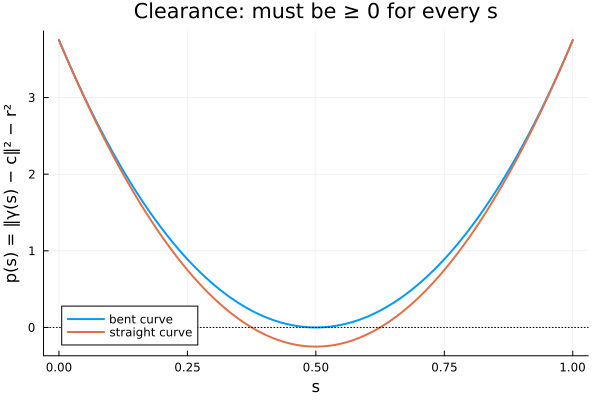

In [8]:
c, r = [0.0, 0.0], 0.5
e = ones(3)
M = (Γbent - c * e')' * (Γbent - c * e') - r^2 * (e * e')
s = 0.3
println("at s = 0.3:  ‖γ(s) - c‖² - r² = ", sum(abs2, γ(Γbent, s) - c) - r^2,
        ",  b₂(s)ᵀ M b₂(s) = ", b(2, s)' * M * b(2, s))

p(Γ, s) = sum(abs2, γ(Γ, s) - c) - r^2
plot(0:0.005:1, s -> p(Γbent, s); label = "bent curve", lw = 2,
     xlabel = "s", ylabel = "p(s) = ‖γ(s) − c‖² − r²", title = "Clearance: must be ≥ 0 for every s")
plot!(0:0.005:1, s -> p(Γstraight, s); label = "straight curve", lw = 2)
hline!([0]; color = :black, ls = :dot, label = "")

### 2.4 An exact certificate for "for all $s$" (Sec. IV, Lemma 2, App. D.2)

**Markov–Lukács theorem (eq. 10).** A polynomial $p$ of degree $2d$ is nonnegative on $[0,1]$ if and
only if
$$p(s)=\sigma_0(s)+s(1-s)\,\sigma_1(s)$$
with $\sigma_0,\sigma_1$ sums of squares of degrees at most $2d$ and $2d-2$.

Read it this way: both terms are *visibly* nonnegative on $[0,1]$ (squares are never negative, and
$s(1-s)\ge0$ there), and the theorem says such a decomposition always exists when $p\ge0$ on $[0,1]$.
A sum of squares is represented by a positive semidefinite **Gram matrix**:
$\sigma_0=b_d^TQ_0b_d$, $\sigma_1=b_{d-1}^TQ_1b_{d-1}$ with $Q_0,Q_1\succeq0$.

**Lemma 2.** The curve avoids the obstacle iff there are $Q_0\succeq0$, $Q_1\succeq0$ whose polynomial
coefficients match those of $p$. In the Bernstein basis, a product of two basis polynomials is a single
basis polynomial of degree $2d$ (eq. 27), so matching coefficients is a weighted sum along anti-diagonals:

$$[\mathcal S_d(M)]_j=\sum_{i+l=j}\frac{\binom di\binom dl}{\binom{2d}{j}}M_{il},\qquad
[\mathcal T_d(N)]_j=\begin{cases}\frac{j(2d-j)}{2d(2d-1)}[\mathcal S_{d-1}(N)]_{j-1}&1\le j\le 2d-1\\0&\text{otherwise}\end{cases}
\tag{32, 33}$$

and the certificate is the $2d+1$ linear equations
$\ \mathcal S_d(M_\Gamma)=\mathcal S_d(Q_0)+\mathcal T_d(Q_1)$, with $M_\Gamma$ the bracket in (7).

The function `clearance_coefficients` takes the matrix of inner products `X` as a *separate argument*
instead of computing $\Gamma^T\Gamma$ itself. For a real curve we pass `X = Γ'Γ`; Section 3 will pass
the relaxed $X$.

In [9]:
S(d, M) = [sum(binomial(d, i) * binomial(d, j - i) / binomial(2d, j) * M[i + 1, j - i + 1]
               for i in max(0, j - d):min(d, j)) for j in 0:2d]

function T(d, N)
    lower = S(d - 1, N)
    return [1 <= j <= 2d - 1 ? j * (2d - j) / (2d * (2d - 1)) * lower[j] : zero(lower[1]) for j in 0:2d]
end

function clearance_coefficients(Γ, X, c, r)
    e = ones(size(Γ, 2))
    M = X - (Γ' * c) * e' - e * (c' * Γ) + (c' * c - r^2) * (e * e')
    return S(size(Γ, 2) - 1, M)
end

function add_certificate!(model, Γ, X, c, r)
    d = size(Γ, 2) - 1
    Q0 = @variable(model, [1:d+1, 1:d+1], PSD)
    Q1 = @variable(model, [1:d, 1:d], PSD)
    @constraint(model, clearance_coefficients(Γ, X, c, r) .== S(d, Q0) + T(d, Q1))
    return Q0, Q1
end

add_certificate! (generic function with 1 method)

**Tiny example 1: products of Bernstein polynomials.** The coefficient matching rests on eq. (27): a product
of two basis polynomials is one basis polynomial of double degree. The smallest case, $d=1$:

$$B_0^1(s)\,B_1^1(s)=(1-s)\,s=\tfrac12\,B_1^2(s),\qquad\text{since } B_1^2(s)=2s(1-s).$$

**Tiny example 2: the bent curve's clearance in Bernstein form.** $\mathcal S_2(M)$ turns the quadratic form
$b_2^TMb_2$ into the five coefficients of $p(s)$ in the degree-4 Bernstein basis. They come out as
$(3.75,\ -0.25,\ -0.917,\ -0.25,\ 3.75)$.

Some coefficients are **negative**, even though $p(s)\ge0$ everywhere. So the quick test "all Bernstein
coefficients $\ge0$" cannot prove this curve is clear of the obstacle. This is why Lemma 2 uses the
Markov–Lukács certificate instead.

**Tiny example 3: the certificate itself.** From the previous tiny example, $p=\tfrac72u^2+\tfrac14u^4$ with
$u=2s-1$. That is already a sum of squares, $\sigma_0=\tfrac72(u)^2+\tfrac14(u^2)^2$, with $\sigma_1=0$. In
the Bernstein basis $u$ has coefficients $(-1,0,1)$ and $u^2$ has $(1,-1,1)$, so its Gram matrix is

$$Q_0=\tfrac72\begin{bmatrix}-1\\0\\1\end{bmatrix}\begin{bmatrix}-1&0&1\end{bmatrix}
+\tfrac14\begin{bmatrix}1\\-1\\1\end{bmatrix}\begin{bmatrix}1&-1&1\end{bmatrix}\succeq0,\qquad Q_1=0.$$

The cell checks that $\mathcal S_2(Q_0)+\mathcal T_2(Q_1)$ gives back the coefficients of $p$. It then asks
the solver for its own certificate, which need not be the same: certificates are not unique. Both must be
PSD and reproduce the same five coefficients.

In [10]:
println("B₀¹B₁¹ at s = 0.3: ", B(1, 0, 0.3) * B(1, 1, 0.3), ",  ½B₁²(0.3) = ", B(2, 1, 0.3) / 2)

coefficients = clearance_coefficients(Γbent, Γbent' * Γbent, c, r)
println("Bernstein coefficients of p: ", round.(coefficients; digits = 4))
println("p(0.3) from them: ", coefficients' * b(4, 0.3), ",  directly: ", p(Γbent, 0.3))

Q0hand = 7/2 * [-1, 0, 1] * [-1, 0, 1]' + 1/4 * [1, -1, 1] * [1, -1, 1]'
println("hand certificate:   S₂(Q₀) + T₂(0) = ", round.(S(2, Q0hand) + T(2, zeros(2, 2)); digits = 4),
        ",  eigenvalues of Q₀: ", round.(eigvals(Q0hand); digits = 4))

model = Model(Hypatia.Optimizer); set_silent(model)
Q0, Q1 = add_certificate!(model, Γbent, Γbent' * Γbent, c, r)
optimize!(model)
println("solver certificate: S₂(Q₀) + T₂(Q₁) = ", round.(S(2, value.(Q0)) + T(2, value.(Q1)); digits = 4),
        ",  eigenvalues: ", round.(eigvals(Symmetric(value.(Q0))); digits = 4), ", ", round.(eigvals(Symmetric(value.(Q1))); digits = 4))

B₀¹B₁¹ at s = 0.3: 0.21,  ½B₁²(0.3) = 0.21
Bernstein coefficients of p: [3.75, -0.25, -0.9167, -0.25, 3.75]
p(0.3) from them: 0.5663999999999999,  directly: 0.5663999999999997
hand certificate:   S₂(Q₀) + T₂(0) = [3.75, -0.25, -0.9167, -0.25, 3.75],  eigenvalues of Q₀: [0.0, 0.75, 7.0]
solver certificate: S₂(Q₀) + T₂(Q₁) = [3.75, -0.25, -0.9167, -0.25, 3.75],  eigenvalues: [-0.0, 2.4635, 5.8577], [0.0, 4.5694]


**Seeing the certificate work on fixed curves.** For a *given* $\Gamma$, Lemma 2 is a convex
feasibility problem: search for $Q_0,Q_1$. Below we ask it about two quadratic curves from $(-2,0)$ to
$(2,0)$ and an obstacle of radius $1/2$ at the origin: one that bends up through the control point
$(0,1)$, and the straight one. Expect the first to be certified (it passes $1/2$ above the centre) and the
second to be infeasible (it goes through the centre).

In [11]:
function certify(Γ, c, r)
    model = Model(Hypatia.Optimizer); set_silent(model)
    add_certificate!(model, Γ, Γ' * Γ, c, r)
    optimize!(model)
    return termination_status(model)
end

c, r = [0.0, 0.0], 0.5
println("bent curve:     ", certify([-2.0 0.0 2.0; 0.0 1.0 0.0], c, r))
println("straight curve: ", certify(Γstraight, c, r))

bent curve:     OPTIMAL
straight curve: INFEASIBLE


## 3. Step 4–6: the relaxation and what it solves

*Where we are:* steps 1–3 were exact. We now have a finite problem with no "for all $s$" left. This
section shows where its nonconvexity sits, relaxes it, and states what the relaxation actually computes.

### 3.1 Problem (P): nonconvex only through $\Gamma^T\Gamma$ (Sec. V-A)

Substituting Lemma 2 into (8) gives

$$
\begin{aligned}
\min_{\Gamma,Q_0,Q_1}\quad & \operatorname{tr}\big(G^{(k)}\Gamma^T\Gamma\big)\\
\text{s.t.}\quad & \mathcal L\big((\Gamma-cu^T)^T(\Gamma-cu^T),\,Q_0,\,Q_1\big)=0,\quad Q_0\succeq0,\ Q_1\succeq0,\\
& \Gamma A=B.
\end{aligned}\tag{P}
$$

Here $\mathcal L$ is the coefficient matching of Lemma 2 and $\Gamma A=B$ the boundary conditions (eq. 9).
By (19), every term is either linear in $\Gamma$, $Q_0$, $Q_1$, or involves the product $\Gamma^T\Gamma$.
That product is the **only** source of nonconvexity: it is what lets a solution "choose a side" of the
obstacle.

### 3.2 The lift: replace $\Gamma^T\Gamma$ by $X\succeq\Gamma^T\Gamma$ (Sec. V-B, eq. 20)

Introduce a new symmetric matrix variable $X$ standing for $\Gamma^T\Gamma$. With $X$ in its place every
expression in (P) becomes linear. The exact requirement $X=\Gamma^T\Gamma$ is nonconvex, so it is relaxed
to the convex inequality $X\succeq\Gamma^T\Gamma$, which by the Schur complement is a linear matrix
inequality:

$$X\succeq\Gamma^T\Gamma\iff\begin{bmatrix}I_n&\Gamma\\ \Gamma^T&X\end{bmatrix}\succeq0. \tag{20}$$

The resulting **(SDP)** minimises $\operatorname{tr}(G^{(k)}X)$ subject to the certificate with $X$ in
place of $\Gamma^T\Gamma$, $\Gamma A=B$, the "tightening" constraint $XA=\Gamma^TB$ (implied when
$X=\Gamma^T\Gamma$, but not after relaxing), and (20).

Since every feasible point of (P) gives a feasible point of (SDP) with $X=\Gamma^T\Gamma$, the SDP's
optimal cost is a **lower bound** on the true optimal cost.

**Fixed endpoints (Sec. V-C).** If the first and last control points are fixed ($\ell=0$), the SDP is not
strictly feasible. The paper's fix, facial reduction, keeps only the free control points
$\Gamma_{\text{free}}$ as unknowns, with a small lifted block $X_{\text{free}}\succeq\Gamma_{\text{free}}^T\Gamma_{\text{free}}$; every
entry of $X$ that involves a fixed control point is an ordinary inner product, linear in
$\Gamma_{\text{free}}$. This also satisfies $\Gamma A=B$ and $XA=\Gamma^TB$ by construction. Section 4.2
builds exactly that SDP for the example, one step at a time.

### 3.3 What the SDP actually solves: paths with extra dimensions (Sec. VI-A)

The paper's key observation is that the relaxation is not just "some convex approximation". It solves,
exactly, a **planning problem in a bigger space**. Give the curve $\rho$ extra coordinates,
$v(s)=Vb_d(s)\in\mathbb R^\rho$ with $V\in\mathbb R^{\rho\times(d+1)}$, so the full curve is
$(\gamma(s),v(s))\in\mathbb R^{n+\rho}$. Keep the obstacle a sphere centred at $(c,0)$ and require the extra
coordinates to start and end at $0$:

$$
\begin{aligned}
\min\quad & \operatorname{tr}\big(G^{(k)}(\Gamma^T\Gamma+V^TV)\big)\\
\text{s.t.}\quad & \mathcal L\big((\Gamma-cu^T)^T(\Gamma-cu^T)+V^TV,\,Q_0,\,Q_1\big)=0,\quad Q_0,Q_1\succeq0,\\
& \Gamma A=B,\quad VA=0.
\end{aligned}\tag{$P_\rho$}
$$

In words: the same problem, but the robot may leave the plane and fly over the obstacle, as long as it
starts and ends in the plane. Extra room can only help, so:

- **Theorem 1.** $c^*_{P_\rho}\ge c^*_{P_{\rho+1}}$: more dimensions never cost more.
- **Theorem 2.** $c^*_{P_\rho}\ge c^*_{SDP}$ for every $\rho$: the SDP is below all of them.
- **Theorem 3.** If $(\Gamma^*,X^*)$ solves (SDP) and $\rho=\operatorname{rank}(X^*-\Gamma^{*T}\Gamma^*)$,
  then any $V^*$ with $V^{*T}V^*=X^*-\Gamma^{*T}\Gamma^*$ makes $(\Gamma^*,V^*)$ optimal for $(P_\rho)$.

So **the SDP finds the cheapest path over all dimensions**, and the "slack" $X^*-\Gamma^{*T}\Gamma^*$
is literally the Gram matrix of the extra coordinates. Lemma 4 bounds how many are needed:
$\rho\le(d+1)-2(\ell+1)$, the number of free control points.

### 3.4 When is the relaxation exact? (Sec. VI-B, C)

- **Theorem 4 (tight cost).** $c^*_{SDP}=c^*_P$ iff $c^*_P=c^*_{P_\rho}$ for all $\rho$: extra dimensions
  do not help.
- **Theorem 5 (recovery).** If for every $\rho$ every minimiser of $(P_\rho)$ has $\Gamma=\Gamma^*$ and
  $V=0$, then every SDP solution has $X=\Gamma^{*T}\Gamma^*$, and $\Gamma^*$ can be read off.

Theorem 5 can fail even when Theorem 4 holds, for example when the original problem has **two** optimal
paths, one on each side of an obstacle. That is exactly the example we now solve.

## 4. The simplest example: one quadratic curve around one circle

*Where we are:* we have the relaxation and the theorems that interpret it. We now solve the smallest case
where tight cost and failed recovery happen together, and read the solution through Theorems 3–5.

**Simplifications.** $n=2$, one segment of degree $d=2$, energy cost $k=1$, one obstacle, and only the
endpoint *positions* fixed ($\ell=0$, velocities free):

- start $q_0=(-2,0)$, goal $q_1=(2,0)$;
- obstacle centred at $c=(0,0)$ with radius $r=1/2$.

Only the middle control point $(a,h)$ is free:

$$\Gamma=\begin{bmatrix}-2&a&2\\0&h&0\end{bmatrix},\qquad
\gamma(s)=\begin{bmatrix}-2+4s+2a\,s(1-s)\\ 2h\,s(1-s)\end{bmatrix}.$$

### 4.1 The answer by hand

**Cost.** $\gamma'(s)=\big(4+2a(1-2s),\ 2h(1-2s)\big)$. With $\int_0^1(1-2s)\,ds=0$ and
$\int_0^1(1-2s)^2ds=\tfrac13$,
$$J=\int_0^1\|\gamma'\|^2ds=16+\tfrac43\,(a^2+h^2).$$

**Constraint.** At $s=\tfrac12$ the curve is at $(a/2,\,h/2)$, which must be at least $\tfrac12$ from the
origin, so $a^2+h^2\ge1$. Hence $J\ge16+\tfrac43=\tfrac{52}{3}\approx17.333$.

**Attained.** $(a,h)=(0,1)$ reaches it, and it really is clear of the obstacle for every $s$: with
$u=2s-1$, $\|\gamma(s)\|^2-\tfrac14=\tfrac72u^2+\tfrac14u^4\ge0$. By symmetry $(0,-1)$ is equally good.

So $c^*_P=52/3$, with **two** optimal paths, one above and one below the obstacle.

The plot shows the obstacle and the two optimal paths, each with its control polygon. The middle control
point sits at distance $1$ from the centre, twice as far as the curve itself passes: control points pull
the curve, they are not waypoints.

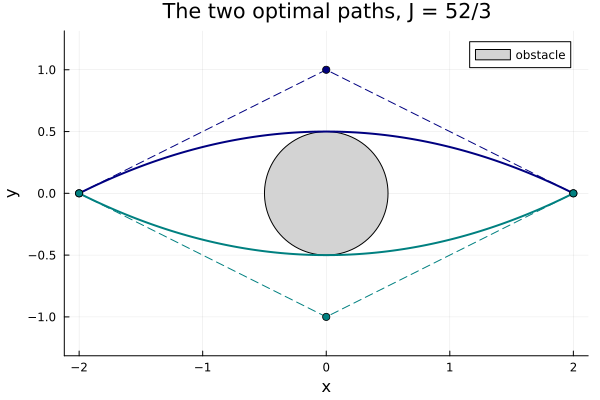

In [12]:
q0, q1, d, k = [-2.0, 0.0], [2.0, 0.0], 2, 1
ss = range(0, 1; length = 201)
path(Γ) = (γx = [γ(Γ, s)[1] for s in ss], γy = [γ(Γ, s)[2] for s in ss])
circle(c, r) = Shape(c[1] .+ r .* cos.(range(0, 2π; length = 100)), c[2] .+ r .* sin.(range(0, 2π; length = 100)))

Γup   = [-2.0 0.0 2.0; 0.0  1.0 0.0]
Γdown = [-2.0 0.0 2.0; 0.0 -1.0 0.0]
fig = plot(circle(c, r); color = :lightgray, label = "obstacle", aspect_ratio = :equal,
           xlabel = "x", ylabel = "y", title = "The two optimal paths, J = 52/3")
for (Γ, col) in ((Γup, :navy), (Γdown, :teal))
    p = path(Γ)
    plot!(fig, p.γx, p.γy; color = col, lw = 2, label = "")
    plot!(fig, Γ[1, :], Γ[2, :]; color = col, ls = :dash, marker = :circle, label = "")
end
fig

### 4.2 Solve the relaxation

Now hand the problem to the SDP of Section 3.2. What to expect from the theorems:

- **Cost:** a lower bound on $52/3$. Lifting into extra dimensions cannot beat $52/3$ here (going over the
  obstacle in a third dimension is just the planar optimum rotated), so by Theorem 4 the bound is exact.
- **Curve:** the problem has two minimisers, so Theorem 5's hypothesis fails and we should not expect to
  read off a valid $\Gamma$.

We build that SDP one piece at a time. With $d=2$ and both endpoints fixed, the only free control point is
the middle one, $\gamma_1=(a,h)$.

**Step 1: an empty model.** Create the optimization problem and choose the solver. Hypatia is an
interior-point solver for conic problems, which include SDPs.

In [13]:
model = Model(Hypatia.Optimizer)
set_silent(model)

**Step 2: the unknowns.** Two things are unknown:
- the free control point $\gamma_1=(a,h)$, a $2\times1$ block of $\Gamma$;
- one number $X_{11}$ standing in for $\|\gamma_1\|^2=a^2+h^2$, the only entry of $X=\Gamma^T\Gamma$ that is
  quadratic in the unknowns (entries are indexed from $0$ like the control points, so the middle one is
  $X_{11}$).

This is the paper's facial reduction (Sec. V-C) for this example: only the free part of $\Gamma$ is
lifted.

In [14]:
@variable(model, γ₁[1:2, 1:1])
@variable(model, X₁₁[1:1, 1:1], Symmetric)

1×1 Symmetric{VariableRef, Matrix{VariableRef}}:
 X₁₁[1,1]

**Step 3: the lift (eq. 20).** The exact problem would require $X_{11}=a^2+h^2$, which is nonconvex. The
relaxation asks only for $X_{11}\ge a^2+h^2$, written as the matrix inequality

$$\begin{bmatrix}1&0&a\\0&1&h\\a&h&X_{11}\end{bmatrix}\succeq0,$$

which, by the Schur complement, says exactly $X_{11}-(a^2+h^2)\ge0$. This is eq. (20) restricted to the free
control point.

In [15]:
@constraint(model, [I γ₁; γ₁' X₁₁] in PSDCone())

[1        0        γ₁[1,1]
 0        1        γ₁[2,1]
 γ₁[1,1]  γ₁[2,1]  X₁₁[1,1]] ∈ PSDCone()

**Step 4: assemble $\Gamma$ and $X$.** The first and last columns of $\Gamma$ are the fixed endpoints
$q_0=(-2,0)$ and $q_1=(2,0)$. Every entry of $X$ that involves an endpoint is an ordinary inner product,
linear in $\gamma_1$; only the middle entry is the new variable:

$$X=\begin{bmatrix}q_0^Tq_0&q_0^T\gamma_1&q_0^Tq_1\\ \gamma_1^Tq_0&X_{11}&\gamma_1^Tq_1\\ q_1^Tq_0&q_1^T\gamma_1&q_1^Tq_1\end{bmatrix}
=\begin{bmatrix}4&-2a&-4\\-2a&X_{11}&2a\\-4&2a&4\end{bmatrix}.$$

Because the endpoint columns are exactly $q_0$ and $q_1$, the boundary conditions $\Gamma A=B$ and the
tightening constraints $XA=\Gamma^TB$ hold automatically. The printed $X$ should match the matrix above.

In [16]:
g = γ₁[:, 1]
Γ = AffExpr[q0 g q1]
X = AffExpr[dot(q0, q0)  dot(q0, g)  dot(q0, q1)
            dot(q0, g)   X₁₁[1, 1]   dot(q1, g)
            dot(q0, q1)  dot(q1, g)  dot(q1, q1)]

3×3 Matrix{AffExpr}:
 4           -2 γ₁[1,1]  -4
 -2 γ₁[1,1]  X₁₁[1,1]    2 γ₁[1,1]
 -4          2 γ₁[1,1]   4

**Step 5: the obstacle (Lemma 2, with $X$ in place of $\Gamma^T\Gamma$).** `add_certificate!` from
Section 2.4 adds the two PSD Gram matrices $Q_0$ ($3\times3$) and $Q_1$ ($2\times2$) and the five equations
matching the degree-4 Bernstein coefficients of the clearance polynomial. Because we pass $X$ rather than
$\Gamma^T\Gamma$, these equations are linear in the unknowns.

In [17]:
Q0, Q1 = add_certificate!(model, Γ, X, c, r)

(VariableRef[_[4] _[5] _[7]; _[5] _[6] _[8]; _[7] _[8] _[9]], VariableRef[_[10] _[11]; _[11] _[12]])

**Step 6: the cost.** $\operatorname{tr}(G^{(1)}X)$, linear in $X$. By the hand computation of Section 4.1
with $a^2+h^2$ replaced by $X_{11}$, expect $16+\tfrac43X_{11}$.

In [18]:
@objective(model, Min, tr(Gk(d, k) * X))
objective_function(model)

1.3333333333333333 X₁₁[1,1] + 16

**Step 7: solve.**

In [19]:
optimize!(model)
termination_status(model)

OPTIMAL::TerminationStatusCode = 1

**Step 8: read off the solution.** $\hat\Gamma$ and $\hat X$ are the solver's values for $\Gamma$ and $X$.
Compare the cost with $52/3$, and look at the middle control point.

In [20]:
Γ̂ = value.(Γ)
X̂ = value.(X)
println("SDP optimal cost:        ", round(objective_value(model); digits = 6))
println("true optimal cost 52/3:  ", round(52 / 3; digits = 6))
println("middle control point:    ", round.(Γ̂[:, 2]; digits = 6))

SDP optimal cost:        17.333333
true optimal cost 52/3:  17.333333
middle control point:    [0.0, -0.019119]


The cost is right, but the middle control point is close to the origin ($h\approx-0.02$): the returned
curve is almost the **straight segment through the obstacle**. Both facts are true at once, and Theorem 3
explains why.

Why $h\approx0$ rather than $h=\pm1$: the certificate and the cost only see the entries of $X$, and with the
obstacle at the origin those do not involve $h$. So every middle point $(0,h)$ with $|h|\le1$ (the LMI needs
$X_{22}=1\ge h^2$) is optimal for the SDP, including the two true paths at $h=\pm1$. An interior-point solver
returns a point in the middle of that optimal set.

### 4.3 Read the solution through Theorem 3

Theorem 3 says: look at the slack $X^*-\Gamma^{*T}\Gamma^*$. Its rank $\rho$ is the number of extra
dimensions the SDP's path uses, and factoring it as $V^{*T}V^*$ gives the extra coordinates
$v(s)=V^*b_d(s)$. Lemma 4 predicts $\rho\le(d+1)-2(\ell+1)=1$ here.

In [21]:
slack = Symmetric(X̂ - Γ̂' * Γ̂)
λ, U = eigen(slack)
println("eigenvalues of X - ΓᵀΓ: ", round.(λ; digits = 6))
ρ = count(>(1e-6), λ)
println("ρ = ", ρ)
V = (sqrt.(λ[end-ρ+1:end]) .* U[:, end-ρ+1:end]')   # ρ × (d+1), so VᵀV = slack
println("V = ", round.(V; digits = 6))

eigenvalues of X - ΓᵀΓ: [0.0, 0.0, 0.999634]
ρ = 1
V = [0.0 0.999817 0.0]


One extra dimension, and $V\approx[0\ \ \pm1\ \ 0]$ (exactly $\sqrt{1-h^2}$ in the middle): the extra
coordinate is $v(s)\approx\pm2s(1-s)$, which is $0$ at both ends and $\approx\pm\tfrac12$ in the middle.

So the SDP's path is (up to the small $h$) the **three-dimensional** curve $(\gamma(s),v(s))=(-2+4s,\ 0,\ \pm2s(1-s))$. It lies
in the vertical $(x,v)$ plane and is exactly the planar optimum, rotated out of the plane: it hops
**over** the obstacle instead of going around it. The obstacle is a sphere centred at $(c,0)$, so this
path clears it, at the same cost $52/3$.

The two plots below show this. Left: the clearance $\|\gamma(s)-c\|^2-r^2$ of the planar curve the SDP
returned (negative: it goes through the obstacle) and of the lifted curve, which adds $\|v(s)\|^2$ (never
negative). Right: the lifted path drawn in its own $(x,v)$ plane.

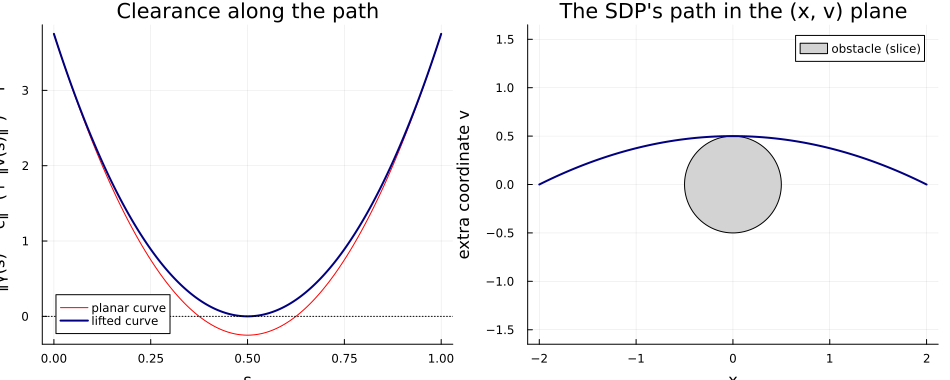

In [22]:
v(s) = V * b(d, s)
planar = [sum(abs2, γ(Γ̂, s) - c) - r^2 for s in ss]
lifted = [sum(abs2, γ(Γ̂, s) - c) + sum(abs2, v(s)) - r^2 for s in ss]
f1 = plot(ss, planar; label = "planar curve", color = :red, xlabel = "s",
          ylabel = "‖γ(s) − c‖² (+ ‖v(s)‖²) − r²", title = "Clearance along the path")
plot!(f1, ss, lifted; label = "lifted curve", color = :navy, lw = 2)
hline!(f1, [0]; color = :black, ls = :dot, label = "")

f2 = plot(circle(c, r); color = :lightgray, label = "obstacle (slice)", aspect_ratio = :equal,
          xlabel = "x", ylabel = "extra coordinate v", title = "The SDP's path in the (x, v) plane")
plot!(f2, [γ(Γ̂, s)[1] for s in ss], [v(s)[1] for s in ss]; color = :navy, lw = 2, label = "")
plot(f1, f2; layout = (1, 2), size = (950, 380))

### 4.4 Getting a planar path back

Theorem 4 holds (the cost $52/3$ is exact) but Theorem 5 does not (two minimisers), so the SDP gives a
**certificate of the optimal cost** but not the path. Here the geometry suggests the repair: rotate the
extra coordinate back into the plane, i.e. put the middle control point at $(a,\ \pm\sqrt{X_{22}-a^2})$,
where $X_{22}$ is the SDP's value for $\|\text{middle control point}\|^2$.

*This rounding is specific to this example; it is not the paper's procedure.* (The paper's RRT
pipeline, Sec. VIII-B, instead adds cutting planes that push the solution back into the original space.)

We then check the recovered curve independently: its cost from Section 2.2, and the Lemma 2 certificate
for the fixed curve from Section 2.4.

In [23]:
a = Γ̂[1, 2]
h = sqrt(X̂[2, 2] - a^2)
Γrecovered = [-2.0 a 2.0; 0.0 h 0.0]
println("recovered middle control point: ", round.(Γrecovered[:, 2]; digits = 6))
println("its cost:                       ", round(tr(Gk(d, k) * Γrecovered' * Γrecovered); digits = 6), "   (52/3 = ", round(52 / 3; digits = 6), ")")
println("Lemma 2 certificate:            ", certify(Γrecovered, c, r))

recovered middle control point: [0.0, 1.0]
its cost:                       17.333333   (52/3 = 17.333333)
Lemma 2 certificate:            OPTIMAL


### 4.5 Variation to try: break the symmetry

Move the obstacle slightly down, to $c=(0,-0.1)$. Now going above is strictly cheaper, so the problem has
a **single** minimiser and Theorem 5 should apply: the SDP should return a valid curve directly, with
$\rho=0$.

By hand, with $a=0$ the binding point is again $s=\tfrac12$, where $(h/2+0.1)^2\ge\tfrac14$ gives $h\ge0.8$,
so $J^*=16+\tfrac43(0.8)^2\approx16.853$. (Hypatia may print a numerical warning while solving this one;
the values below are still accurate to the digits shown.) The cell repeats Steps 1–8 of Section 4.2 in one
place, with only the obstacle centre changed.

In [24]:
c2 = [0.0, -0.1]
model2 = Model(Hypatia.Optimizer); set_silent(model2)
@variable(model2, γ₁[1:2, 1:1])
@variable(model2, X₁₁[1:1, 1:1], Symmetric)
@constraint(model2, [I γ₁; γ₁' X₁₁] in PSDCone())
g = γ₁[:, 1]
Γ2 = AffExpr[q0 g q1]
X2 = AffExpr[dot(q0, q0)  dot(q0, g)  dot(q0, q1)
             dot(q0, g)   X₁₁[1, 1]   dot(q1, g)
             dot(q0, q1)  dot(q1, g)  dot(q1, q1)]
add_certificate!(model2, Γ2, X2, c2, r)
@objective(model2, Min, tr(Gk(d, k) * X2))
optimize!(model2)

Γ̂2, X̂2 = value.(Γ2), value.(X2)
println("SDP cost: ", round(objective_value(model2); digits = 6), "   (by hand ≈ 16.853)")
println("middle control point: ", round.(Γ̂2[:, 2]; digits = 4), "   (by hand (0, 0.8))")
println("eigenvalues of X - ΓᵀΓ: ", round.(eigvals(Symmetric(X̂2 - Γ̂2' * Γ̂2)); digits = 6))

┌ Warning: cannot step in centering direction
└ @ Hypatia.Solvers ~/.julia/packages/Hypatia/iRl7L/src/Solvers/steppers/combined.jl:111


SDP cost: 16.853333   (by hand ≈ 16.853)
middle control point: [-0.0, 0.8]   (by hand (0, 0.8))
eigenvalues of X - ΓᵀΓ: [0.0, 0.0, 0.0]


## 5. Summary

| paper step | what we saw |
|---|---|
| polynomial curves, cost $\operatorname{tr}(G^{(k)}\Gamma^T\Gamma)$ (Sec. III) | the cost of a curve is a fixed matrix applied to the inner products of its control points |
| Lemma 2 (Sec. IV) | "clear of the obstacle for every $s$" is an exact, checkable certificate: the bent curve passed, the straight one failed |
| (P) and the lift $X\succeq\Gamma^T\Gamma$ (Sec. V) | all nonconvexity sits in $\Gamma^T\Gamma$; relaxing it gives a convex SDP and a lower bound |
| Theorems 1–3 (Sec. VI-A) | the SDP's answer is the best path when extra dimensions are allowed; here, a path hopping over the obstacle in a third dimension |
| Theorems 4–5 (Sec. VI-B, C) | the cost $52/3$ was exact, but with two optimal paths the curve itself could not be read off; breaking the symmetry restored recovery |

**References**
- B. P. Graesdal, A. Amice, P. A. Parrilo, R. Tedrake, *Semidefinite Relaxations for Collision-Free
  Motion Planning*, [arXiv:2606.14063](https://arxiv.org/abs/2606.14063): Sec. III–VI, App. D.
- [JuMP: semidefinite constraints](https://jump.dev/JuMP.jl/stable/manual/constraints/#Semidefinite-constraints),
  [Hypatia.jl](https://github.com/jump-dev/Hypatia.jl).